# 02 Impute Protein Data


In [1]:
import msmu as mm
import matplotlib.pyplot as plt
import pimmslearn.plotting as pmp
import pimmslearn.sampling as pms

from pimmslearn.plotting.defaults import color_model_mapping
from pimmslearn.sklearn.cf_transformer import CollaborativeFilteringTransformer
from fastai.torch_core import set_seed

pmp.make_large_descriptors("8")

index_name: str = "Sample ID"
column_name: str = "protein group"
frac_non_train: float = 0.1
frac_mnar: float = 0.05
random_state: int = 42

set_seed(random_state, reproducible=True)

/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Load the processed protein data


In [2]:
mdata = mm.read_h5mu("MSV000089280.h5mu")

In [3]:
df = mdata["protein"].to_df()
df.index.name = "Sample ID"
df.columns.name = "protein group"

## Inspect the missing-value pattern


/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/pimmslearn/plotting/data.py:323: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax = ax[0]  # returned series due to by argument?


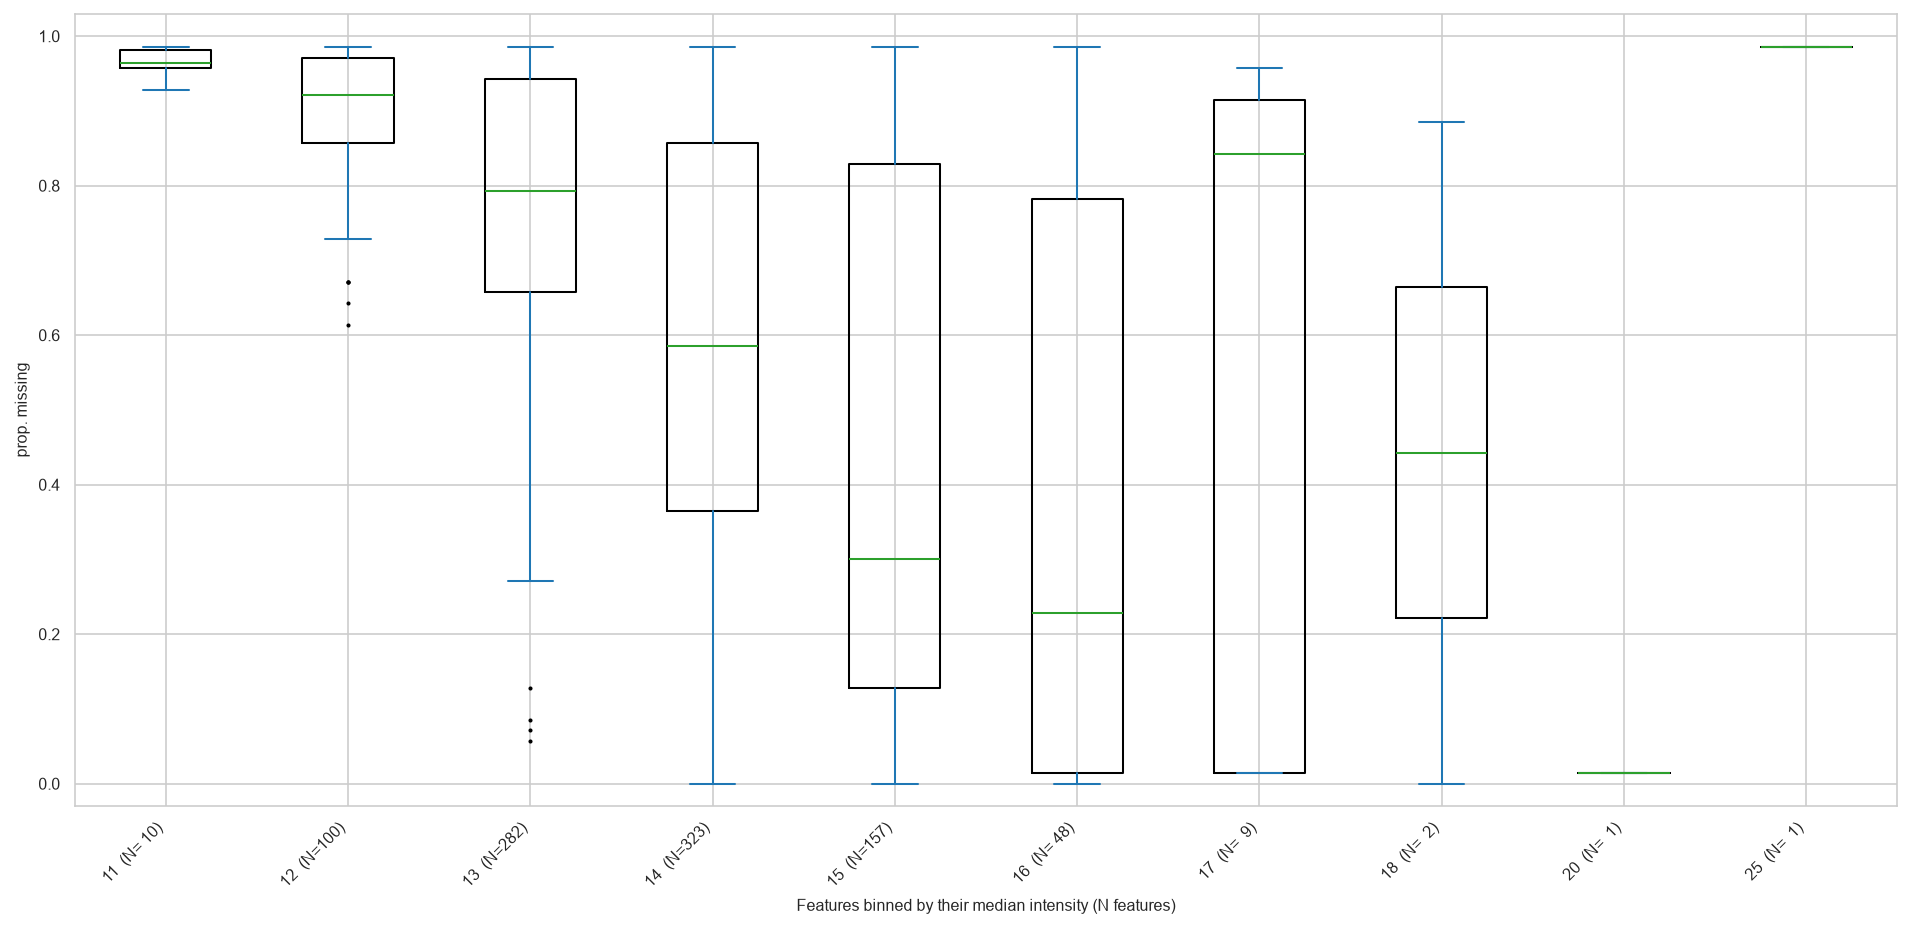

In [4]:
ax = pmp.data.plot_feat_median_over_prop_missing(data=df, type="boxplot")

## Fit the collaborative-filtering model


In [5]:
df = df.stack().to_frame("intensity")

splits, thresholds, fake_na_mcar, fake_na_mnar = pms.sample_mnar_mcar(
    df_long=df,
    frac_non_train=frac_non_train,
    frac_mnar=frac_mnar,
)
splits = pms.check_split_integrity(splits)

/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/pimmslearn/sampling.py:208: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  loc=float(quantile_frac),
/Users/jl/Scripts/msmu/docs/tutorials/2024_Fulcher/.venv/lib/python3.13/site-packages/pimmslearn/sampling.py:209: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  scale=float(0.3 * df_long.std()),


suggested_lr.valley = 0.00363


epoch,train_loss,valid_loss,time
0,8.805157,9.193611,00:00
1,8.743397,9.041893,00:00
2,8.700479,8.717175,00:00
3,8.521395,8.148706,00:00
4,8.243607,7.261636,00:00
5,7.852963,6.100307,00:00
6,7.347463,4.806377,00:00
7,6.754587,3.572668,00:00
8,6.113807,2.561528,00:00
9,5.483077,1.839937,00:00


,target_column,'intensity'
,sample_column,'Sample ID'
,item_column,'protein group'
,out_folder,Path('runs/scikit_interface')
,n_factors,15
,batch_size,4096
Name,Type,Value
epochs_trained_,int,20


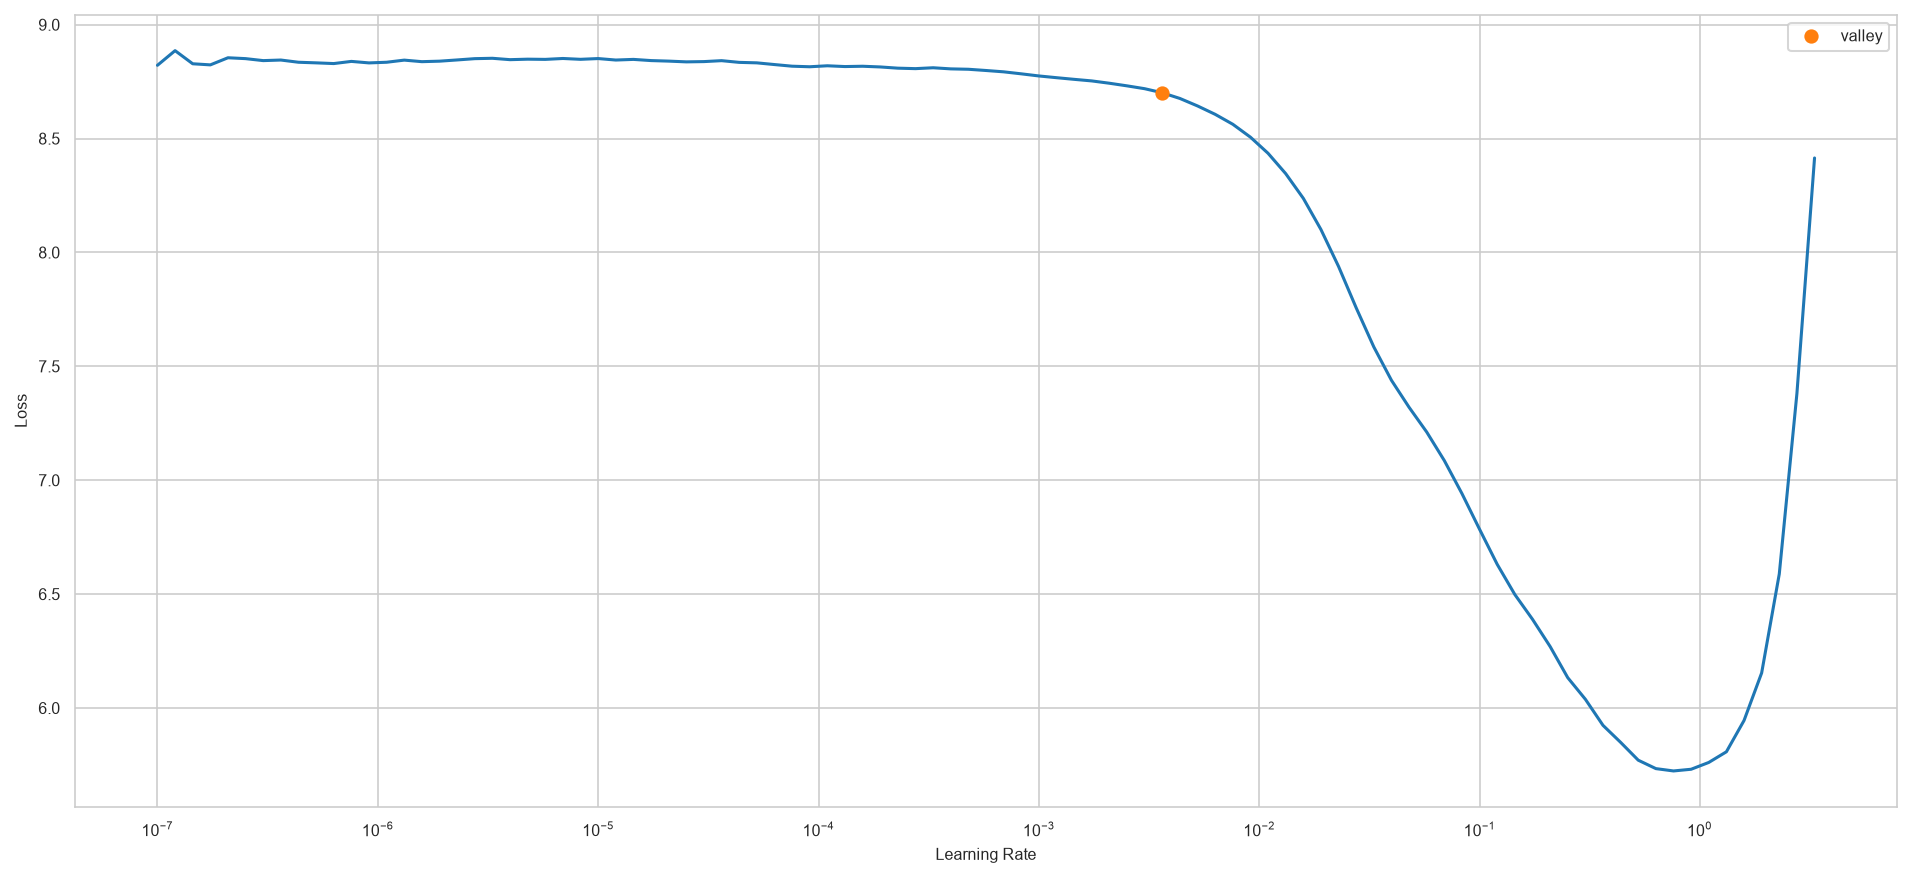

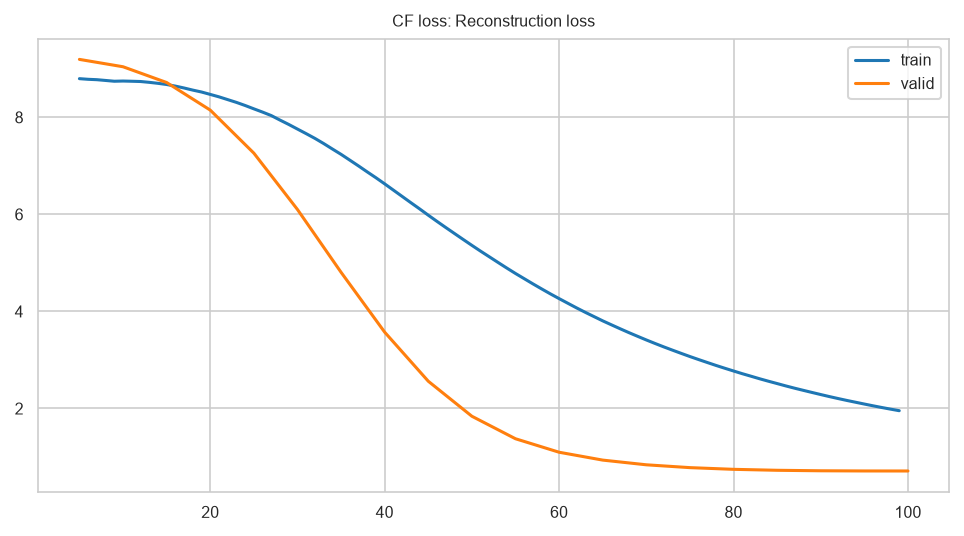

In [6]:
cf_model = CollaborativeFilteringTransformer(
    target_column="intensity",
    sample_column="Sample ID",
    item_column="protein group",
    out_folder="runs/scikit_interface",
)

cf_model.fit(splits.train_X, splits.val_y, cuda=False, epochs_max=20)

In [7]:
df_imputed = cf_model.transform(df).unstack()
assert df_imputed.isna().sum().sum() == 0

## Inspect the completed matrix


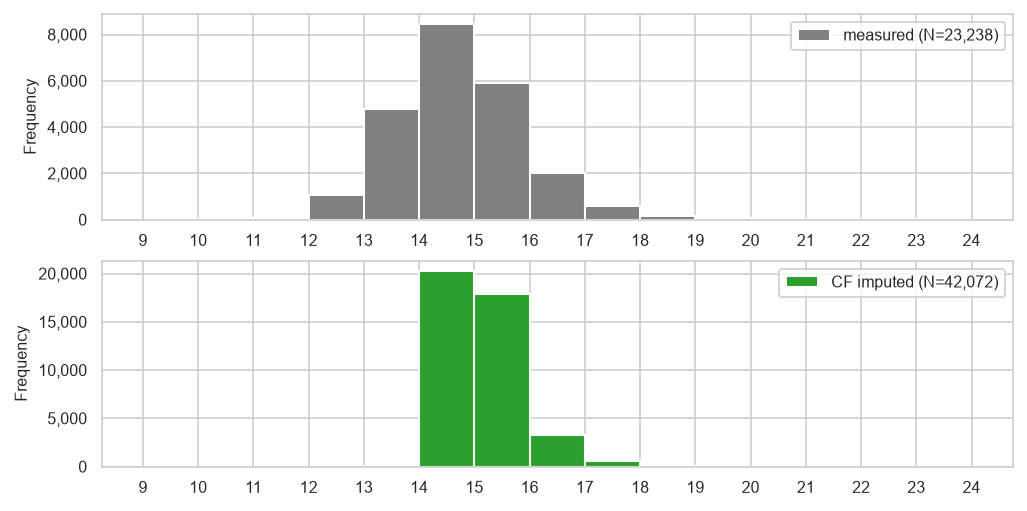

In [8]:
df_imputed = df_imputed.stack()  # long-format
observed = df_imputed.loc[df.index]
imputed = df_imputed.loc[df_imputed.index.difference(df.index)]
df_imputed = df_imputed.unstack()  # back to wide-format
# some checks
assert len(df) == len(observed)
assert df_imputed.shape[0] * df_imputed.shape[1] == len(imputed) + len(observed)

fig, axes = plt.subplots(2, figsize=(8, 4))

min_max = pmp.data.get_min_max_iterable([observed, imputed])
label_template = "{method} (N={n:,d})"
ax, _ = pmp.data.plot_histogram_intensities(
    observed,
    ax=axes[0],
    min_max=min_max,
    label=label_template.format(
        method="measured",
        n=len(observed),
    ),
    color="grey",
    alpha=1,
)
_ = ax.legend()
ax, _ = pmp.data.plot_histogram_intensities(
    imputed,
    ax=axes[1],
    min_max=min_max,
    label=label_template.format(
        method="CF imputed",
        n=len(imputed),
    ),
    color=color_model_mapping["CF"],
    alpha=1,
)
_ = ax.legend()

## Store the imputed layer


In [9]:
mdata.mod["protein"].layers["imputed"] = df_imputed

mdata

MuData object with n_obs × n_vars = 70 × 85218
  obs:	'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[label]', 'comment[instrument]', 'comment[cleavage agent details]', 'comment[modification parameters]', 'comment[modification parameters].1', 'comment[modification parameters].2', 'comment[fraction identifier]', 'comment[technical replicate]', 'comment[file uri]', 'factor value[sample]', 'factor value[condition]', 'factor value[rna data file]'
  uns:	'_log', 'sdrf'
  3 modalities
    psm:	70 × 80375
      obs:	'source name', 'characteristics[organism]', 'characteristics[organism part]', 'characteristics[disease]', 'characteristics[cell line]', 'characteristics[biological replicate]', 'assay name', 'technology type', 'comment[proteomics data acquisition method]', 'comment[l

## Save imputed MuData object


In [10]:
mdata.write_h5mu("MSV000089280_imputed.h5mu")